In [ ]:

from google.colab import drive
drive.mount("/content/gdrive")

from pathlib import Path
import os
import json
import zipfile
import hashlib
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageFile
from sklearn.model_selection import train_test_split

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

DRIVE_ROOT = Path("/content/gdrive/MyDrive")
ZIP_PATH = DRIVE_ROOT / "cell_images.zip"
OUTPUT_DIR = DRIVE_ROOT / "malaria_cnn_outputs"
EXTRACT_DIR = Path("/content/malaria_dataset")

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Drive:", DRIVE_ROOT)
print("Dataset ZIP exists:", ZIP_PATH.is_file())
print("Output directory:", OUTPUT_DIR)

assert ZIP_PATH.is_file(), (
    f"Cannot find {ZIP_PATH}. Check your Google Drive."
)


Mounted at /content/gdrive
Drive: /content/gdrive/MyDrive
Dataset ZIP exists: True
Output directory: /content/gdrive/MyDrive/malaria_cnn_outputs


In [ ]:

def extract_dataset():
    EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

    def find_class_dirs():
        parasitized = [
            p for p in EXTRACT_DIR.rglob("Parasitized")
            if p.is_dir()
        ]
        uninfected = [
            p for p in EXTRACT_DIR.rglob("Uninfected")
            if p.is_dir()
        ]

        for p in parasitized:
            for u in uninfected:
                if p.parent == u.parent:
                    return p.parent, p, u

        return None

    found = find_class_dirs()

    if found is None:
        print("Extracting dataset ZIP...")
        with zipfile.ZipFile(ZIP_PATH, "r") as z:
            z.extractall(EXTRACT_DIR)
        found = find_class_dirs()

    if found is None:
        raise FileNotFoundError(
            "Could not locate matching Parasitized and Uninfected "
            "folders after extraction. Inspect the ZIP structure."
        )

    return found


DATASET_DIR, PARASITIZED_DIR, UNINFECTED_DIR = extract_dataset()

print("Dataset directory:", DATASET_DIR)
print("Parasitized directory:", PARASITIZED_DIR)
print("Uninfected directory:", UNINFECTED_DIR)


Extracting dataset ZIP...
Dataset directory: /content/malaria_dataset/cell_images
Parasitized directory: /content/malaria_dataset/cell_images/Parasitized
Uninfected directory: /content/malaria_dataset/cell_images/Uninfected


In [ ]:

SUPPORTED_EXTENSIONS = {".png", ".jpg", ".jpeg"}

records = []
bad_files = []

for label, label_id, folder in [
    ("Uninfected", 0, UNINFECTED_DIR),
    ("Parasitized", 1, PARASITIZED_DIR),
]:
    for path in sorted(folder.iterdir()):
        if not path.is_file():
            continue
        if path.suffix.lower() not in SUPPORTED_EXTENSIONS:
            continue

        try:
            with Image.open(path) as im:
                im.verify()

            with Image.open(path) as im:
                width, height = im.size
                mode = im.mode

            records.append({
                "relative_path": str(path.relative_to(DATASET_DIR)),
                "filename": path.name,
                "label": label,
                "label_id": label_id,
                "width": width,
                "height": height,
                "mode": mode,
                "file_size_bytes": path.stat().st_size
            })

        except Exception as e:
            bad_files.append({
                "filepath": str(path),
                "error": str(e)
            })

df = pd.DataFrame(records)

print("Readable images:", len(df))
print("Unreadable images:", len(bad_files))
print("\nClass counts:")
print(df["label"].value_counts())

if bad_files:
    pd.DataFrame(bad_files).to_csv(
        OUTPUT_DIR / "unreadable_images.csv", index=False
    )

assert len(df) > 0, "No readable images found."
assert set(df["label"].unique()) == {"Uninfected", "Parasitized"}


Readable images: 27558
Unreadable images: 0

Class counts:
label
Uninfected     13779
Parasitized    13779
Name: count, dtype: int64


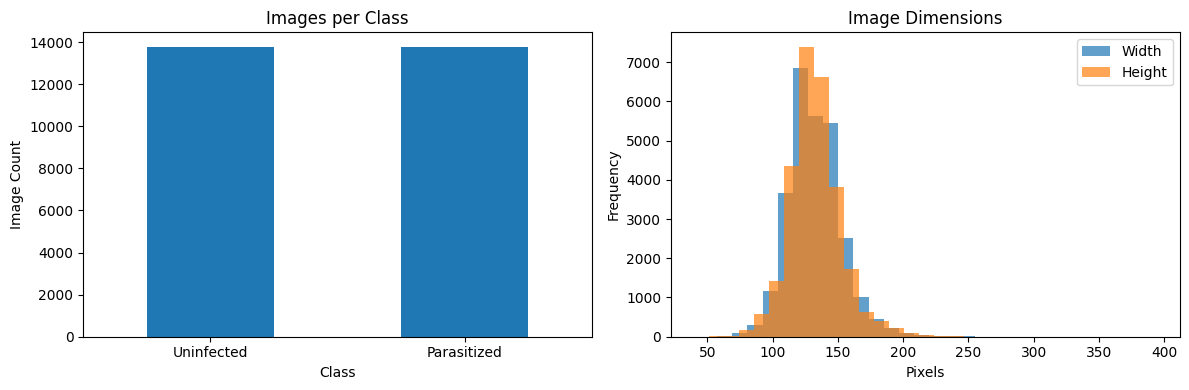


Dimension summary:
              width        height  file_size_bytes
count  27558.000000  27558.000000     27558.000000
mean     132.487154    132.983453     12046.868314
std       20.015949     20.619650      3030.380310
min       46.000000     40.000000      1418.000000
25%      121.000000    121.000000     10020.250000
50%      130.000000    130.000000     11778.000000
75%      142.000000    145.000000     13793.000000
max      394.000000    385.000000     36865.000000

Color modes:
mode
RGB    27558
Name: count, dtype: int64


In [ ]:

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df["label"].value_counts().reindex(
    ["Uninfected", "Parasitized"]
).plot(kind="bar", ax=axes[0])

axes[0].set_title("Images per Class")
axes[0].set_xlabel("Class")
axes[0].set_ylabel("Image Count")
axes[0].tick_params(axis="x", rotation=0)

axes[1].hist(df["width"], bins=30, alpha=0.7, label="Width")
axes[1].hist(df["height"], bins=30, alpha=0.7, label="Height")
axes[1].set_title("Image Dimensions")
axes[1].set_xlabel("Pixels")
axes[1].set_ylabel("Frequency")
axes[1].legend()

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "dataset_eda.png", dpi=200)
plt.show()

print("\nDimension summary:")
print(df[["width", "height", "file_size_bytes"]].describe())

print("\nColor modes:")
print(df["mode"].value_counts())


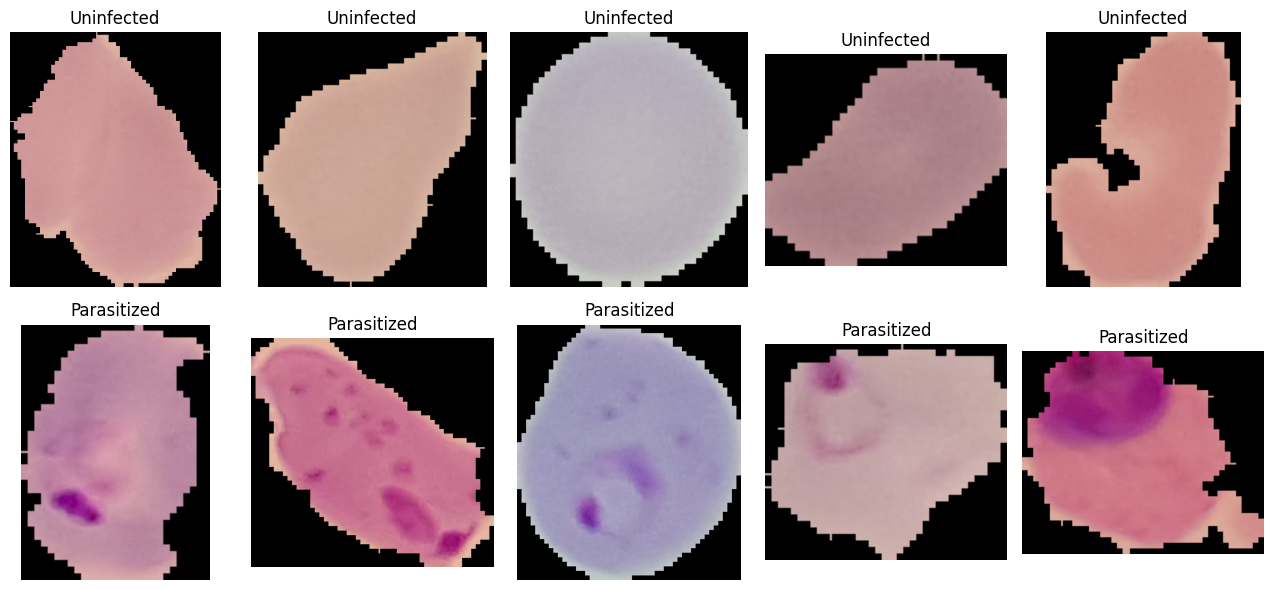

In [ ]:

fig, axes = plt.subplots(2, 5, figsize=(13, 6))

for row, label in enumerate(["Uninfected", "Parasitized"]):
    samples = df[df["label"] == label].sample(
        n=min(5, (df["label"] == label).sum()),
        random_state=SEED
    )

    for col, (_, item) in enumerate(samples.iterrows()):
        path = DATASET_DIR / item["relative_path"]

        with Image.open(path) as im:
            axes[row, col].imshow(im.convert("RGB"))

        axes[row, col].set_title(label)
        axes[row, col].axis("off")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "sample_images.png", dpi=200)
plt.show()


In [ ]:

train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["label_id"],
    random_state=SEED
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label_id"],
    random_state=SEED
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

train_df.to_csv(OUTPUT_DIR / "train_manifest.csv", index=False)
val_df.to_csv(OUTPUT_DIR / "validation_manifest.csv", index=False)
test_df.to_csv(OUTPUT_DIR / "test_manifest.csv", index=False)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))
print("Total:", len(train_df) + len(val_df) + len(test_df))

for name, split in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(f"\n{name} class distribution:")
    print(split["label"].value_counts())

assert len(train_df) + len(val_df) + len(test_df) == len(df)
assert set(train_df["relative_path"]).isdisjoint(val_df["relative_path"])
assert set(train_df["relative_path"]).isdisjoint(test_df["relative_path"])
assert set(val_df["relative_path"]).isdisjoint(test_df["relative_path"])


Train: 19290
Validation: 4134
Test: 4134
Total: 27558

Train class distribution:
label
Parasitized    9645
Uninfected     9645
Name: count, dtype: int64

Validation class distribution:
label
Uninfected     2067
Parasitized    2067
Name: count, dtype: int64

Test class distribution:
label
Uninfected     2067
Parasitized    2067
Name: count, dtype: int64


In [ ]:

config = {
    "project": "Malaria Cell Image Classification",
    "image_height": 128,
    "image_width": 128,
    "channels": 3,
    "normalization": "divide pixel values by 255.0",
    "batch_size": 32,
    "seed": SEED,
    "class_mapping": {
        "Uninfected": 0,
        "Parasitized": 1
    },
    "split_ratios": {
        "train": 0.70,
        "validation": 0.15,
        "test": 0.15
    },
    "path_format": "relative to DATASET_DIR"
}

with open(OUTPUT_DIR / "preprocessing_config.json", "w") as f:
    json.dump(config, f, indent=4)

df.to_csv(OUTPUT_DIR / "image_metadata.csv", index=False)

print("Preprocessing stage complete.")
print("Saved files:")
for p in sorted(OUTPUT_DIR.iterdir()):
    if p.is_file():
        print(p.name)


Preprocessing stage complete.
Saved files:
dataset_eda.png
image_metadata.csv
preprocessing_config.json
sample_images.png
test_manifest.csv
train_manifest.csv
validation_manifest.csv
